# Study schedule demo

Runs `scheduling/scheduler.py` on one synthetic student with hours predicted by the saved model.

## 1. Setup

Student 8 has eight assignments due from Oct 5 to Oct 18, 2026, a typical two-week load. The CSV has no status column, so every assignment starts as `Not Started`. The scheduler runs once on Oct 5 and is given all eight at that time, even those assigned later in the window.

In [1]:
import sys
from dataclasses import replace
from datetime import date, datetime, time, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT))

from ml.src.predict import predict_hours
from scheduling.scheduler import AssignmentInput, CommitmentInput, generate_schedule

# Chart styling: matches ml/notebooks/01_eda.ipynb
BLUE = "#2a78d6"
INK = "#52514e"
GRID = "#e1e0d9"
SURFACE = "#fcfcfb"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "xtick.color": INK,
    "ytick.color": INK,
})

# One fixed color per assignment id, in deadline order
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
ORANGE = SERIES[1]
COMMITMENT_GRAY = "#c3c2b7"

STUDENT_ID = 8
START = datetime(2026, 10, 5, 9, 0)  # a Monday
WINDOW_END = date(2026, 10, 18)

df = pd.read_csv(ROOT / "ml" / "data" / "synthetic_assignments.csv", parse_dates=["due_date"])
window = df[
    (df["student_id"] == STUDENT_ID)
    & (df["due_date"].dt.date >= START.date())
    & (df["due_date"].dt.date <= WINDOW_END)
].sort_values(["due_date", "course", "title"]).reset_index(drop=True)

window["id"] = window.index + 1
window["name"] = window["course"] + " " + window["title"]
window["predicted_hrs"] = [predict_hours(row) for row in window.to_dict("records")]

assignments = [
    AssignmentInput(row.id, row.name, row.due_date.date(), row.predicted_hrs, "Not Started")
    for row in window.itertuples(index=False)
]
names = dict(zip(window["id"], window["name"]))

window[["id", "course", "title", "type", "difficulty", "due_date", "predicted_hrs", "actual_hrs"]]

,id,course,title,type,difficulty,due_date,predicted_hrs,actual_hrs
0,1,HUM 103,Lab 2,Lab,Medium,2026-10-06,3.75,3.50
1,2,MA 222,Homework 1,Homework,Easy,2026-10-08,3.50,3.00
2,3,CS 385,Homework 1,Homework,Medium,2026-10-09,4.00,4.50
3,4,CS 385,Reading 1,Reading,Medium,2026-10-10,1.50,1.75
4,5,CS 546,Reading 2,Reading,Medium,2026-10-12,1.50,1.75
5,6,CS 546,Reading 3,Reading,Medium,2026-10-13,1.50,1.75
6,7,CS 546,Reading 4,Reading,Hard,2026-10-17,2.25,1.25
7,8,HUM 103,Lab 3,Lab,Medium,2026-10-17,3.75,5.00


In [2]:
# Sample weekly class schedule (0=Mon ... 6=Sun)
commitments = [
    CommitmentInput(0, time(10, 0), time(11, 15)),
    CommitmentInput(2, time(10, 0), time(11, 15)),
    CommitmentInput(0, time(14, 0), time(15, 15)),
    CommitmentInput(2, time(14, 0), time(15, 15)),
    CommitmentInput(1, time(11, 0), time(12, 15)),
    CommitmentInput(3, time(11, 0), time(12, 15)),
    CommitmentInput(1, time(15, 30), time(16, 45)),
    CommitmentInput(3, time(15, 30), time(16, 45)),
    CommitmentInput(4, time(13, 0), time(15, 45)),
]

DAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
pd.DataFrame(
    {"day": DAY_NAMES[c.day_of_week], "start": c.start_time, "end": c.end_time}
    for c in commitments
)

,day,start,end
0,Mon,10:00:00,11:15:00
1,Wed,10:00:00,11:15:00
2,Mon,14:00:00,15:15:00
3,Wed,14:00:00,15:15:00
4,Tue,11:00:00,12:15:00
5,Thu,11:00:00,12:15:00
6,Tue,15:30:00,16:45:00
7,Thu,15:30:00,16:45:00
8,Fri,13:00:00,15:45:00


## 2. Generate the schedule

All settings are the `SchedulerConfig` defaults.

In [3]:
result = generate_schedule(assignments, commitments, START)


def hours_of(block):
    """Length of a study block in hours."""
    start = block.start_time.hour + block.start_time.minute / 60
    end = block.end_time.hour + block.end_time.minute / 60
    return end - start


blocks_table = pd.DataFrame(
    {
        "date": b.date,
        "day": DAY_NAMES[b.date.weekday()],
        "start": b.start_time.strftime("%H:%M"),
        "end": b.end_time.strftime("%H:%M"),
        "hours": hours_of(b),
        "assignment": names[b.assignment_id],
    }
    for b in result.blocks
)
print(f"Blocks generated: {len(result.blocks)}")
print(f"Hours scheduled: {blocks_table['hours'].sum()}")
blocks_table

Blocks generated: 18
Hours scheduled: 20.25


,date,day,start,end,hours,assignment
0,2026-10-05,Mon,09:00,10:00,1.00,HUM 103 Lab 2
1,2026-10-05,Mon,11:15,12:15,1.00,HUM 103 Lab 2
2,2026-10-05,Mon,12:30,14:00,1.50,MA 222 Homework 1
3,2026-10-05,Mon,15:15,15:45,0.50,MA 222 Homework 1
4,2026-10-06,Tue,09:00,10:30,1.50,MA 222 Homework 1
5,2026-10-06,Tue,12:15,14:15,2.00,CS 385 Homework 1
6,2026-10-06,Tue,14:30,15:00,0.50,CS 385 Reading 1
7,2026-10-07,Wed,09:00,10:00,1.00,CS 385 Homework 1
8,2026-10-07,Wed,11:15,12:15,1.00,CS 385 Homework 1
9,2026-10-07,Wed,12:30,13:30,1.00,CS 385 Reading 1


## 3. Weekly calendar

Commitments are gray. Study blocks are colored by assignment and carry the assignment's id, so they can be read without relying on color.

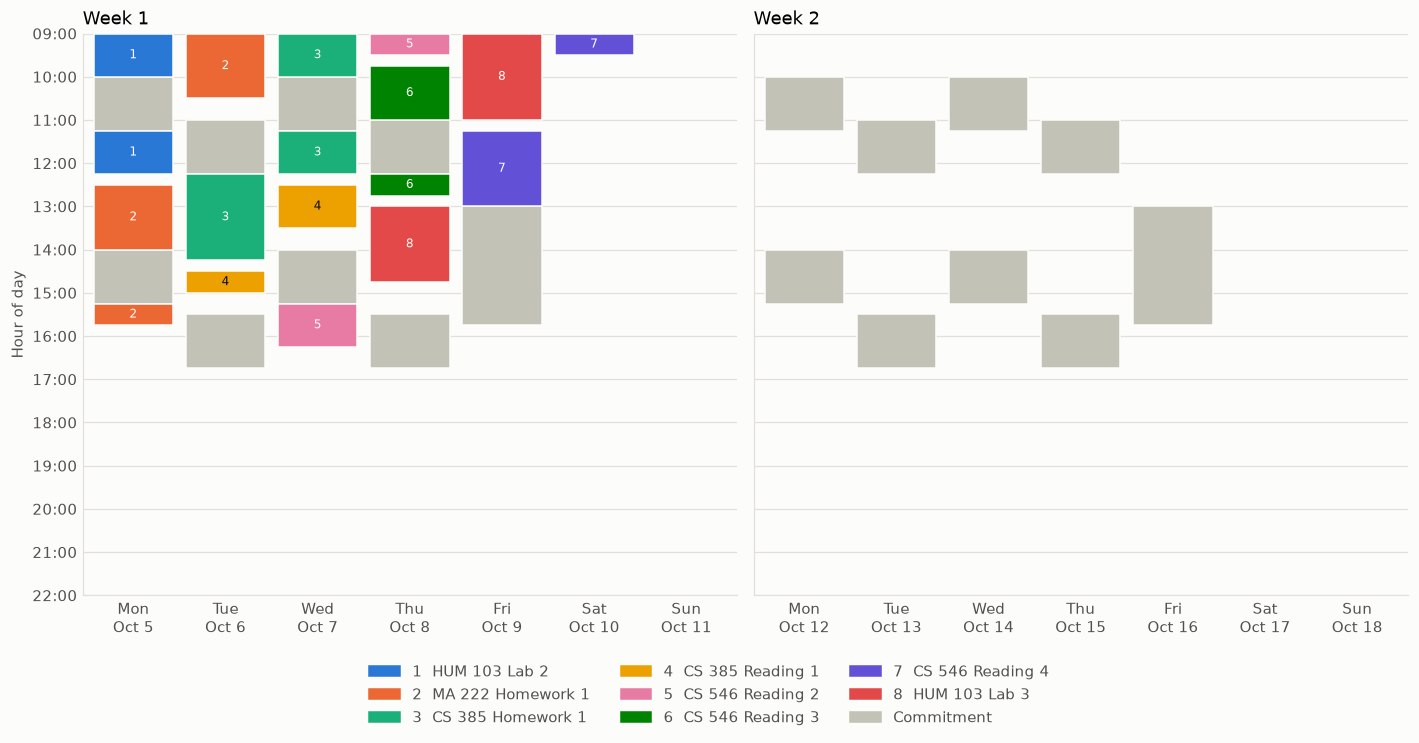

In [4]:
def to_hours(clock):
    return clock.hour + clock.minute / 60


def draw_week(ax, monday, blocks):
    """Draw one Monday-to-Sunday week of commitments and study blocks."""
    days = [monday + timedelta(days=offset) for offset in range(7)]

    for commitment in commitments:
        start = to_hours(commitment.start_time)
        ax.bar(commitment.day_of_week, to_hours(commitment.end_time) - start, bottom=start,
               width=0.86, color=COMMITMENT_GRAY, edgecolor=SURFACE, linewidth=1)

    for block in blocks:
        if block.date not in days:
            continue
        color = SERIES[block.assignment_id - 1]
        start = to_hours(block.start_time)
        height = hours_of(block)
        x = block.date.weekday()
        ax.bar(x, height, bottom=start, width=0.86, color=color, edgecolor=SURFACE, linewidth=1)
        text_color = "#0b0b0b" if color == "#eda100" else "#ffffff"
        ax.text(x, start + height / 2, str(block.assignment_id), ha="center", va="center",
                fontsize=8, color=text_color)

    ax.set_xticks(range(7), [f"{DAY_NAMES[d.weekday()]}\n{d:%b} {d.day}" for d in days])
    ax.set_xlim(-0.55, 6.55)
    ax.set_ylim(22, 9)
    ax.set_yticks(range(9, 23), [f"{hour:02d}:00" for hour in range(9, 23)])
    ax.grid(axis="x", visible=False)
    ax.tick_params(length=0)


def legend_handles():
    """Legend entries for every assignment, then commitments."""
    handles = [
        plt.Rectangle((0, 0), 1, 1, color=SERIES[i - 1], label=f"{i}  {name}")
        for i, name in names.items()
    ]
    handles.append(plt.Rectangle((0, 0), 1, 1, color=COMMITMENT_GRAY, label="Commitment"))
    return handles


fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
draw_week(axes[0], START.date(), result.blocks)
draw_week(axes[1], START.date() + timedelta(days=7), result.blocks)
axes[0].set_title("Week 1", loc="left")
axes[1].set_title("Week 2", loc="left")
axes[0].set_ylabel("Hour of day")
fig.legend(handles=legend_handles(), loc="lower center", ncol=3, frameon=False,
           labelcolor=INK, bbox_to_anchor=(0.5, -0.13))
fig.tight_layout()
plt.show()

## 4. At-risk report

An assignment is at risk when its hours do not all fit before the day ahead of its deadline.

In [5]:
def at_risk_table(schedule, source):
    """Join at-risk rows with each assignment's due date and hours needed."""
    by_id = {a.id: a for a in source}
    return pd.DataFrame(
        [
            {
                "id": row["assignment_id"],
                "assignment": row["title"],
                "due_date": by_id[row["assignment_id"]].due_date,
                "hours_needed": by_id[row["assignment_id"]].hours_needed,
                "hours_scheduled": row["hours_scheduled"],
                "hours_short": row["hours_short"],
            }
            for row in schedule.at_risk
        ],
        columns=["id", "assignment", "due_date", "hours_needed", "hours_scheduled", "hours_short"],
    )


at_risk_table(result, assignments)

,id,assignment,due_date,hours_needed,hours_scheduled,hours_short
0,1,HUM 103 Lab 2,2026-10-06,3.75,2.0,1.75


## 5. Stress test

Double every predicted hour and rerun, to see how the plan degrades if the student works at half the predicted speed.

In [6]:
doubled = [replace(a, hours_needed=a.hours_needed * 2) for a in assignments]
stressed = generate_schedule(doubled, commitments, START)

summary = pd.DataFrame(
    {
        "hours_needed": [sum(a.hours_needed for a in assignments), sum(a.hours_needed for a in doubled)],
        "blocks": [len(result.blocks), len(stressed.blocks)],
        "assignments_at_risk": [len(result.at_risk), len(stressed.at_risk)],
        "hours_short": [
            sum(row["hours_short"] for row in result.at_risk),
            sum(row["hours_short"] for row in stressed.at_risk),
        ],
    },
    index=["Predicted hours", "Doubled hours"],
)
summary

,hours_needed,blocks,assignments_at_risk,hours_short
Predicted hours,21.75,18,1,1.75
Doubled hours,43.50,28,3,8.50


In [7]:
at_risk_table(stressed, doubled)

,id,assignment,due_date,hours_needed,hours_scheduled,hours_short
0,1,HUM 103 Lab 2,2026-10-06,7.5,2.0,5.5
1,2,MA 222 Homework 1,2026-10-08,7.0,6.0,1.0
2,3,CS 385 Homework 1,2026-10-09,8.0,6.0,2.0


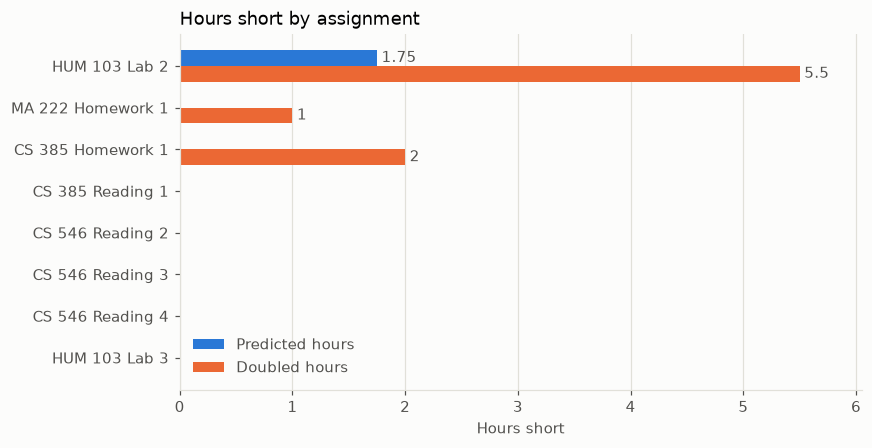

In [8]:
def short_by_id(schedule):
    return {row["assignment_id"]: row["hours_short"] for row in schedule.at_risk}


base_short = short_by_id(result)
stress_short = short_by_id(stressed)
ids = list(names)
positions = range(len(ids))
bar_height = 0.38

fig, ax = plt.subplots(figsize=(8, 4.2))
base_bars = ax.barh([p - bar_height / 2 for p in positions], [base_short.get(i, 0) for i in ids],
                    height=bar_height, color=BLUE, label="Predicted hours")
stress_bars = ax.barh([p + bar_height / 2 for p in positions], [stress_short.get(i, 0) for i in ids],
                      height=bar_height, color=ORANGE, label="Doubled hours")
for bars in (base_bars, stress_bars):
    labels = [f"{bar.get_width():g}" if bar.get_width() else "" for bar in bars]
    ax.bar_label(bars, labels=labels, padding=3, color=INK)
ax.set_yticks(list(positions), [names[i] for i in ids])
ax.invert_yaxis()
ax.set_title("Hours short by assignment", loc="left")
ax.set_xlabel("Hours short")
ax.grid(axis="y", visible=False)
ax.margins(x=0.1)
ax.legend(frameon=False, labelcolor=INK)
plt.show()

## 6. Takeaways

- **Most of the plan fits.** The predicted 21.75 hours produce 18 blocks, and only one of the eight assignments is at risk.
- **The at-risk item is limited by the rules, not by free time.** HUM 103 Lab 2 is due Oct 6, so Oct 5 is its only allowed day, and the 2-hour per-assignment cap leaves it 1.75 hours short.
- **Risk grows with workload, starting at the earliest deadlines.** Doubling the hours raises the at-risk count from 1 to 3 and the shortfall from 1.75 to 8.5 hours. All three are the first deadlines, because later assignments still have enough days.
- **Greedy scheduling front-loads work.** Every block lands between Oct 5 and Oct 10 and week 2 stays empty, which leaves slack for slips but starts long-deadline work early.
- **Small remainders can add time.** CS 546 Reading 3 gets 1.75 hours for a 1.5-hour need, because its 0.25-hour remainder became a 0.5-hour minimum block. That is why 20.25 hours are scheduled when only 20 were needed from the assignments that fit.
- **Predictions carry error.** The saved model's test MAE is about 1.7 hours, so the stress test is a useful check on how much slack a plan really has.
